# 01 · Data: CPCB + weather → one clean table per station

**Input**
- `data/1_download/cpcb/<station>/` — official CPCB hourly files (1 CSV per station per year, 2018 → Sep 2026)
- `data/1_download/stations.csv` — 33 stations with latitude / longitude
- Open-Meteo ERA5 weather (downloaded here, free, no key)

**Output:** `data/2_clean/<station>.parquet` — one row per IST hour with
true PM2.5 / PM10 (what the models must predict), CO / NO2 / O3 (drive our gas sensors) and weather.

In [1]:
# imports
import time
from pathlib import Path

import httpx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
# folders and the time range of the data
DATA = Path("../data")
DOWNLOAD = DATA / "1_download"
CLEAN = DATA / "2_clean"
CLEAN.mkdir(parents=True, exist_ok=True)

START, END = "2018-01-01", "2026-09-30"

In [3]:
# the 33 stations
stations = pd.read_csv(DOWNLOAD / "stations.csv")
stations

,station_id,name,lat,lon,elevation_m
0,alipur_delhi_dpcc,"Alipur, Delhi - DPCC",28.815329,77.153010,215.0
1,anand_vihar_delhi_dpcc,"Anand Vihar, Delhi - DPCC",28.648817,77.315616,207.0
2,arya_nagar_bahadurgarh_hspcb,"Arya Nagar, Bahadurgarh - HSPCB",28.670100,76.925400,213.0
3,aya_nagar_delhi_iitm,"Aya Nagar, Delhi - IITM",28.470691,77.109936,270.0
4,bawana_delhi_dpcc,"Bawana, Delhi - DPCC",28.776200,77.051074,219.0
5,burari_crossing_delhi_iitm,"Burari Crossing, Delhi - IITM",28.725650,77.201157,208.0
6,crri_mathura_road_delhi_iitm,"CRRI Mathura Road, Delhi - IITM",28.551201,77.273574,218.0
7,dr_karni_singh_shooting_range_delhi_dpcc,"Dr. Karni Singh Shooting Range, Delhi - DPCC",28.498571,77.264840,251.0
8,dtu_delhi_cpcb,"DTU, Delhi - CPCB",28.750050,77.111261,216.0
9,dwarka_sector_8_delhi_dpcc,"Dwarka-Sector 8, Delhi - DPCC",28.571027,77.071901,217.0


## 1. CPCB files
One file = one station, one year, one row per hour.
`Timestamp` = **start** of the IST hour (`10:00` means 10:00-11:00 IST). We checked this against a second copy
of the same data (OpenAQ): shifting by ±1 hour made the match clearly worse.

In [4]:
# look at one raw file
raw = pd.read_csv(DOWNLOAD / "cpcb" / "anand_vihar_delhi_dpcc" / "Raw_Data_2023_site_301_anand_vihar_delhi_dpcc_1hr.csv")
raw.head()

,Timestamp,PM2.5 (µg/m³),PM10 (µg/m³),NO (µg/m³),NO2 (µg/m³),NOx (ppb),NH3 (µg/m³),SO2 (µg/m³),CO (mg/m³),Ozone (µg/m³),...,MP-Xylene (µg/m³),AT (°C),RH (%),WS (m/s),WD (deg),RF (mm),TOT-RF (mm),SR (W/mt2),BP (mmHg),VWS (m/s)
0,2023-01-01 00:00:00,148.000000,266.00,107.800,83.950,132.625,32.925,15.925,2.700000,8.300,...,NaN,14.250,86.675,0.425,230.50,NaN,0.0,6.625,974.975,NaN
1,2023-01-01 01:00:00,145.000000,257.00,53.550,69.975,80.900,31.425,13.050,2.250000,13.500,...,NaN,14.025,88.125,0.425,198.50,NaN,0.0,6.625,975.000,NaN
2,2023-01-01 02:00:00,158.666667,238.75,35.500,63.950,62.800,39.900,12.250,2.400000,8.650,...,NaN,13.875,89.650,0.500,216.25,NaN,0.0,6.600,975.075,NaN
3,2023-01-01 03:00:00,171.000000,248.00,124.425,58.950,132.800,29.175,14.000,2.700000,8.075,...,NaN,13.400,90.575,0.300,244.00,NaN,0.0,6.625,975.075,NaN
4,2023-01-01 04:00:00,132.666667,204.25,163.175,62.900,166.500,27.550,15.650,2.933333,7.775,...,NaN,13.125,92.825,0.300,239.00,NaN,0.0,6.600,975.325,NaN


We only keep the columns we need. Gas units must match our sensor formulas (ppb / ppm):

$$\text{ppb} = \frac{\mu g/m^3 \times 24.45}{\text{molar mass}} \qquad \text{ppm} = \frac{mg/m^3 \times 24.45}{\text{molar mass}}$$

24.45 L/mol = volume of one mole of gas at 25 °C. Molar masses: CO 28.01, NO2 46.01, O3 48.00 g/mol.

In [5]:
# which CPCB columns we keep, and their new names
COLUMNS = {"PM2.5 (µg/m³)": "pm25", "PM10 (µg/m³)": "pm10", "CO (mg/m³)": "co_ppm",
           "NO2 (µg/m³)": "no2_ppb", "Ozone (µg/m³)": "o3_ppb"}

# unit conversion factors (see formula above)
TO_PPM_PPB = {"co_ppm": 24.45 / 28.01, "no2_ppb": 24.45 / 46.01, "o3_ppb": 24.45 / 48.00}

In [6]:
# read all yearly files of one station into one table (index = UTC time of the IST hour start)
def read_cpcb(station_id):
    files = sorted((DOWNLOAD / "cpcb" / station_id).glob("*.csv"))
    df = pd.concat([pd.read_csv(f, usecols=["Timestamp", *COLUMNS]) for f in files])
    df = df.rename(columns=COLUMNS)
    ist_time = pd.to_datetime(df.pop("Timestamp")).dt.tz_localize("Asia/Kolkata")
    df.index = ist_time.dt.tz_convert("UTC")
    for col, factor in TO_PPM_PPB.items():
        df[col] = df[col] * factor
    df = df[~df.index.duplicated()]
    return df.sort_index()

In [7]:
# try it on one station
read_cpcb("anand_vihar_delhi_dpcc").describe().round(1)

,pm25,pm10,no2_ppb,co_ppm,o3_ppb
count,69128.0,68151.0,67777.0,64653.0,68376.0
mean,128.4,285.7,40.1,1.8,14.6
std,116.6,188.6,27.4,1.2,15.0
min,0.2,1.0,0.0,0.0,0.0
25%,50.0,144.2,20.6,1.0,5.0
50%,87.0,245.0,34.7,1.5,9.3
75%,170.8,383.0,53.0,2.3,19.1
max,998.0,1000.0,265.3,17.2,474.7


## 2. Weather (Open-Meteo ERA5)
- We ask for UTC (`timezone=GMT`) because Open-Meteo's India time-zone mode labels the half hour wrongly.
- One IST hour (e.g. 10:00-11:00 IST = 04:30-05:30 UTC) is centred on one UTC hour, so
  $$x_{IST} = \tfrac{1}{8}x_{UTC-1} + \tfrac{3}{4}x_{UTC} + \tfrac{1}{8}x_{UTC+1}$$
- Rain and sunshine are "total of the previous hour", so an IST hour gets half of two UTC values.
- Wind speed + direction are turned into the east (u) and north (v) parts: $u = -s\sin\theta,\ v = -s\cos\theta$.

In [8]:
# weather variables we download
WEATHER_VARS = ["temperature_2m", "relative_humidity_2m", "surface_pressure", "wind_speed_10m",
                "wind_direction_10m", "precipitation", "shortwave_radiation"]

In [9]:
# download hourly weather (UTC) for one place and date range
def fetch_weather(lat, lon, start, end):
    params = dict(latitude=round(lat, 4), longitude=round(lon, 4), start_date=start, end_date=end,
                  hourly=",".join(WEATHER_VARS), models="era5", timezone="GMT", wind_speed_unit="ms")
    r = httpx.get("https://archive-api.open-meteo.com/v1/archive", params=params, timeout=120)
    r.raise_for_status()
    hourly = r.json()["hourly"]
    df = pd.DataFrame({k: hourly[k] for k in WEATHER_VARS}, dtype=float)
    df.insert(0, "epoch", (pd.to_datetime(hourly["time"], utc=True) - pd.Timestamp(0, tz="UTC")) // pd.Timedelta("1s"))
    time.sleep(20)  # free API: be polite
    return df

In [10]:
# get the weather of one station (saved to disk, only missing parts are downloaded)
def get_weather(station):
    path = DOWNLOAD / "weather" / f"{station.station_id}.parquet"
    if path.exists():
        df = pd.read_parquet(path)
    else:
        years = [fetch_weather(station.lat, station.lon, f"{y - 1}-12-31", f"{y}-12-31") for y in range(2018, 2026)]
        df = pd.concat(years)
    last_day = pd.to_datetime(df.epoch.max(), unit="s").date()
    need_until = (pd.Timestamp(END) + pd.Timedelta(days=1)).date()
    if last_day < need_until:
        df = pd.concat([df, fetch_weather(station.lat, station.lon, str(last_day), str(need_until))])
    df = df.drop_duplicates("epoch").sort_values("epoch")
    df.to_parquet(path, index=False)
    return df

In [11]:
# convert UTC weather to IST hours (formulas above)
def weather_to_ist(w):
    w = w.set_index("epoch").sort_index()
    w = w.reindex(np.arange(w.index.min(), w.index.max() + 3600, 3600))   # no missing hours
    angle = np.deg2rad(w.wind_direction_10m)
    point_values = {"era5_t2m": w.temperature_2m, "era5_rh2m": w.relative_humidity_2m, "era5_sp": w.surface_pressure,
                    "era5_u10": -w.wind_speed_10m * np.sin(angle), "era5_v10": -w.wind_speed_10m * np.cos(angle)}
    out = pd.DataFrame(index=pd.to_datetime(w.index - 1800, unit="s", utc=True))   # IST hour starts 30 min earlier
    for name, s in point_values.items():
        out[name] = (0.125 * s.shift(1) + 0.75 * s + 0.125 * s.shift(-1)).to_numpy()
    out["era5_precip"] = (0.5 * w.precipitation + 0.5 * w.precipitation.shift(-1)).to_numpy()
    out["era5_swrad"] = (0.5 * w.shortwave_radiation + 0.5 * w.shortwave_radiation.shift(-1)).to_numpy()
    return out

## 3. Cleaning rules (garbage in = garbage out)
| rule | why |
|---|---|
| negative value → removed | concentrations cannot be negative |
| PM2.5 > 1500, PM10 > 3000 µg/m³ → removed | beyond the instruments' range |
| PM2.5 > 1.05 × PM10 → both removed | PM2.5 is part of PM10 |
| same value 6 hours in a row → removed | stuck instrument |
| Hampel spike → removed | value far from its 24-h median, see below |

**Hampel filter** on $z = \ln(1+PM)$: flag hour $t$ if $|z_t - \text{median}_{24h}| > 3 \times \max(1.4826\cdot \text{MAD}_{24h},\ 0.2)$.
Only short flagged runs (≤ 3 h) are removed: long runs are real pollution episodes.

In [12]:
# stuck instrument: the same value for 6 or more hours
def is_flatline(s, hours=6):
    run_id = (s != s.shift()).cumsum()
    return s.notna() & (s.groupby(run_id).transform("size") >= hours)

In [13]:
# Hampel filter: short spikes far from the 24-hour median
def is_hampel_spike(s, k=3, floor=0.2, max_run=3):
    z = np.log1p(s)
    median = z.rolling(25, center=True, min_periods=6).median()
    mad = (z - median).abs().rolling(25, center=True, min_periods=6).median() * 1.4826
    spike = ((z - median).abs() > k * np.maximum(mad, floor)).fillna(False)
    run_length = spike.groupby((spike != spike.shift()).cumsum()).transform("size")
    return spike & (run_length <= max_run)

In [14]:
# apply all cleaning rules; also count how many values each rule removed
def clean_air(df):
    df = df.copy()
    removed = {}

    def remove(mask, cols, rule):
        removed[rule] = removed.get(rule, 0) + int(mask.sum())
        df.loc[mask, cols] = np.nan

    for col in COLUMNS.values():
        remove(df[col] < 0, col, "negative")
    remove(df.pm25 > 1500, "pm25", "too high")
    remove(df.pm10 > 3000, "pm10", "too high")
    remove(df.pm25 > 1.05 * df.pm10, ["pm25", "pm10"], "PM2.5 > PM10")
    for col in COLUMNS.values():
        remove(is_flatline(df[col]), col, "stuck 6 h")
    for col in ("pm25", "pm10"):
        remove(is_hampel_spike(df[col]), col, "Hampel spike")
    return df, removed

## 4. Build the clean table of every station
The simulator's "true weather" is ERA5 (one source for every station). Dew point with the Magnus formula:
$$g = \ln\frac{RH}{100} + \frac{17.625\,T}{243.04 + T}, \qquad T_d = \frac{243.04\,g}{17.625 - g}$$

In [15]:
# every IST hour from START to END (as UTC times)
hours = pd.date_range(pd.Timestamp(START, tz="Asia/Kolkata"), pd.Timestamp(END + " 23:00", tz="Asia/Kolkata"),
                      freq="h").tz_convert("UTC")
len(hours)

76680

In [16]:
# one station: air + weather -> clean table
def build_station(station):
    air, removed = clean_air(read_cpcb(station.station_id).reindex(hours))
    df = air.join(weather_to_ist(get_weather(station)).reindex(hours))
    df["t"], df["rh"], df["p"] = df.era5_t2m, df.era5_rh2m, df.era5_sp
    df["wind_u"], df["wind_v"] = df.era5_u10, df.era5_v10
    df["precip"], df["swrad"] = df.era5_precip, df.era5_swrad
    g = np.log(df.rh.clip(lower=1) / 100) + 17.625 * df.t / (243.04 + df.t)
    df["td"] = 243.04 * g / (17.625 - g)
    df = df.rename_axis("ts").reset_index()
    df["ist_hour"] = df.ts.dt.tz_convert("Asia/Kolkata").dt.hour
    return df, removed

In [17]:
# run all stations (skips stations that are already done)
report = []
for station in stations.itertuples():
    out_file = CLEAN / f"{station.station_id}.parquet"
    if out_file.exists():
        continue
    df, removed = build_station(station)
    df.to_parquet(out_file, index=False)
    report.append({"station": station.station_id, "PM2.5 %": round(100 * df.pm25.notna().mean()), **removed})
pd.DataFrame(report)

""


## 5. Check the result

In [18]:
# load the clean tables (only the air columns)
air_cols = ["ts", "pm25", "pm10", "co_ppm", "no2_ppb", "o3_ppb"]
clean_all = pd.concat([pd.read_parquet(p, columns=air_cols).assign(station=p.stem) for p in sorted(CLEAN.glob("*.parquet"))])
ist = clean_all.ts.dt.tz_convert("Asia/Kolkata")
print(len(clean_all), "station-hours")

2530440 station-hours


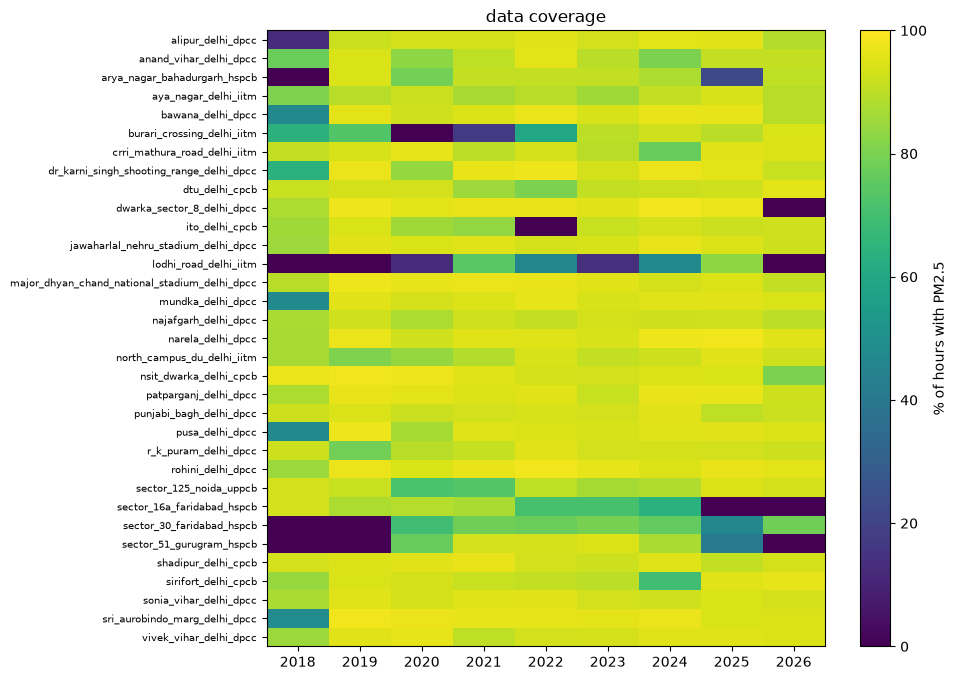

In [19]:
# % of hours with PM2.5, per station and year
coverage = clean_all.pm25.notna().groupby([clean_all.station, ist.dt.year]).mean().unstack() * 100
plt.figure(figsize=(9, 8))
plt.imshow(coverage, aspect="auto", cmap="viridis", vmin=0, vmax=100)
plt.xticks(range(len(coverage.columns)), coverage.columns)
plt.yticks(range(len(coverage)), coverage.index, fontsize=7)
plt.colorbar(label="% of hours with PM2.5")
plt.title("data coverage")
plt.show()

In [20]:
# typical values per season (Delhi: winter is the worst)
season = pd.cut(ist.dt.month % 12, [-1, 2, 5, 9, 11], labels=["winter", "pre-monsoon", "monsoon", "post-monsoon"])
clean_all.groupby(season, observed=True)[["pm25", "pm10", "co_ppm", "no2_ppb", "o3_ppb"]].median().round(2)

,pm25,pm10,co_ppm,no2_ppb,o3_ppb
ts,,,,,
winter,140.75,242.50,1.07,20.85,8.20
pre-monsoon,63.65,177.55,0.79,15.73,15.07
monsoon,36.25,95.00,0.72,11.28,10.49
post-monsoon,134.04,264.25,1.16,20.98,9.02


In [21]:
# how many hours with a PM target in each split (train / validation / test)
split = np.select([ist.dt.year <= 2023, ist.dt.year == 2024], ["train 2018-23", "val 2024"], "test 2025-26")
(clean_all.pm25.notna() & clean_all.pm10.notna()).groupby(split).sum()

test 2025-26      410960
train 2018-23    1324052
val 2024          248810
dtype: int64